# Automated Dental Caries and Plaque Detection from Intraoral Radiographs
## Clinical Diagnostic AI Pipeline: Semantic Segmentation with UNet

### Project Overview
Dental caries (tooth decay) and bacterial plaque represent the most prevalent oral diseases worldwide. Conventional detection relies heavily on visual examination and manual interpretation of intraoral dental radiographs (periapical / bitewing X-rays). However, early-stage enamel demineralization presents subtle grayscale radiolucencies with low contrast, leading to inter-observer variability and missed early diagnoses.

### Key Objectives
1. **Localize and Segment Carious Lesions**: Train a deep learning **UNet** semantic segmentation architecture to accurately delineate dental cavities and periapical pathology on intraoral radiographs.
2. **Handle Multi-Modal Clinical Data**: Integrate intraoral periapical radiographs (`Intraoral Radiographic Database for Periapical Les`) with intraoral surface imaging (`ODS_dataset`) to provide a complete diagnostic suite covering **Dental Caries**, **Periapical Lesions**, and **Bacterial Plaque / Calculus**.
3. **Rigorous Clinical Evaluation**: Optimize and report **Dice Similarity Coefficient (DSC)**, **Diagnostic Sensitivity (Recall)**, **Specificity**, **Precision**, and **IoU**, emphasizing the minimization of False Negatives (missed decay).
4. **Export for Deployment**: Save serialized model checkpoints ready to power an interactive, clinician-facing **Streamlit** diagnostic dashboard.

---

In [11]:
# ==============================================================================
# SECTION 1: Environment Setup, Dependencies & Hardware Acceleration
# ==============================================================================

import os
import glob
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_recall_curve

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

# Set random seeds for clinical reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Verify device and hardware acceleration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[*] Execution device: {device}")

if torch.cuda.is_available():
    print(f"[*] GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"[*] Total VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[!] Running on CPU.")
    print("    Tip: If you have an NVIDIA GPU, install CUDA PyTorch for ~10x-20x training acceleration:")
    print("    pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124")


[*] Execution device: cuda
[*] GPU Model: NVIDIA GeForce RTX 5060 Laptop GPU
[*] Total VRAM: 7.93 GB


---
## Section 2: Data Ingestion & Polygon-to-Mask Rasterization Engine

The primary radiographic dataset (`Datasets/Intraoral Radiographic Database for Periapical Les`) provides intraoral radiographs paired with YOLO-style normalized polygon annotations:
$$\text{Line format: } \text{class\_id} \quad x_1 \quad y_1 \quad x_2 \quad y_2 \dots x_n \quad y_n \quad (x, y \in [0, 1])$$

Classes in this dataset are:
- `0`: **Caries** (cavities / demineralized tooth decay)
- `1`: **Lesion_Periapical** (apical periodontitis / periapical abscess)
- `2`: **Restoration** (fillings, crowns, endodontic materials)

*Note on Data Integrity*: Many medical annotation files generated on Windows include a UTF-8 Byte Order Mark (`\ufeff`). Our parser explicitly handles `encoding='utf-8-sig'` to prevent parsing errors.

In [12]:
# ==============================================================================
# SECTION 2: Dataset Path Resolution & Polygon Rasterization Functions
# ==============================================================================

# Resolve repository root whether executed from 'Notebooks/' or repository root
notebook_dir = Path(os.getcwd()).resolve()
PROJECT_ROOT = notebook_dir.parent if notebook_dir.name == 'Notebooks' else notebook_dir
print(f"[*] Project root: {PROJECT_ROOT}")

# Define dataset paths
PERIAPICAL_DIR = PROJECT_ROOT / "Datasets" / "Intraoral Radiographic Database for Periapical Les"
PERIAPICAL_IMG_DIR = PERIAPICAL_DIR / "images"
PERIAPICAL_LBL_DIR = PERIAPICAL_DIR / "labels"
PERIAPICAL_CLASSES_FILE = PERIAPICAL_DIR / "classes.txt"

ODS_DIR = PROJECT_ROOT / "Datasets" / "ODS_dataset"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Read periapical classes
if PERIAPICAL_CLASSES_FILE.exists():
    with open(PERIAPICAL_CLASSES_FILE, 'r', encoding='utf-8-sig') as f:
        PERIAPICAL_CLASSES = [line.strip() for line in f if line.strip()]
else:
    PERIAPICAL_CLASSES = ['Caries', 'Lesion_Periapical', 'Restoration']

print(f"[*] Radiographic pathology classes: {PERIAPICAL_CLASSES}")

def parse_yolo_polygons(lbl_path, width, height, target_class=0):
    """
    Converts normalized polygon vertices into a dense binary 2D mask.
    target_class: 0 = Caries (primary focus), 1 = Periapical Lesion, 2 = Restoration
    """
    mask = np.zeros((height, width), dtype=np.uint8)
    if not os.path.exists(lbl_path):
        return mask
    
    with open(lbl_path, 'r', encoding='utf-8-sig') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > 1:
                cls_id = int(parts[0])
                if cls_id == target_class:
                    coords = [float(x) for x in parts[1:]]
                    pts = np.array(coords).reshape(-1, 2)
                    pts[:, 0] = np.clip(pts[:, 0] * width, 0, width - 1)
                    pts[:, 1] = np.clip(pts[:, 1] * height, 0, height - 1)
                    poly = pts.astype(np.int32)
                    cv2.fillPoly(mask, [poly], 1)
    return mask

# Index all 916 periapical radiographs and extract metadata
records = []
img_files = sorted(list(PERIAPICAL_IMG_DIR.glob('*.*')))

print(f"[*] Indexing {len(img_files)} periapical radiographs...")
for img_path in tqdm(img_files, desc="Indexing radiographs"):
    stem = img_path.stem
    lbl_path = PERIAPICAL_LBL_DIR / f"{stem}.txt"
    if not lbl_path.exists():
        continue
    
    classes_in_file = set()
    caries_count = 0
    periapical_count = 0
    restoration_count = 0
    
    with open(lbl_path, 'r', encoding='utf-8-sig') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > 1:
                cid = int(parts[0])
                classes_in_file.add(cid)
                if cid == 0: caries_count += 1
                elif cid == 1: periapical_count += 1
                elif cid == 2: restoration_count += 1
                
    records.append({
        'stem': stem,
        'image_path': str(img_path),
        'label_path': str(lbl_path),
        'has_caries': int(0 in classes_in_file),
        'caries_count': caries_count,
        'has_periapical': int(1 in classes_in_file),
        'periapical_count': periapical_count,
        'has_restoration': int(2 in classes_in_file),
        'restoration_count': restoration_count
    })

df_periapical = pd.DataFrame(records)
print(f"[*] Successfully indexed {len(df_periapical)} radiographs.")
print(f"    - Radiographs with Caries: {df_periapical['has_caries'].sum()} ({df_periapical['has_caries'].mean()*100:.1f}%)")
print(f"    - Total Caries Lesions:    {df_periapical['caries_count'].sum()}")
print(f"    - Periapical Lesions:      {df_periapical['has_periapical'].sum()}")
print(f"    - Restorations:            {df_periapical['has_restoration'].sum()}")


[*] Project root: D:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs
[*] Radiographic pathology classes: ['Caries', 'Lesion_Periapical', 'Restoration']
[*] Indexing 916 periapical radiographs...


Indexing radiographs:   0%|          | 0/916 [00:00<?, ?it/s]

[*] Successfully indexed 916 radiographs.
    - Radiographs with Caries: 221 (24.1%)
    - Total Caries Lesions:    352
    - Periapical Lesions:      561
    - Restorations:            800


---
## Section 3: Exploratory Data Analysis (EDA) & Radiograph Enhancement (CLAHE)

Dental X-rays often suffer from **low dynamic contrast**, exposure variations between anatomical structures (dense enamel vs. alveolar bone), and quantum sensor noise. 

**Contrast Limited Adaptive Histogram Equalization (CLAHE)** enhances local contrast by dividing the image into contextual tiles (e.g. $8\times 8$) and redistributing the histogram within each tile while clipping contrast amplification at `clipLimit=2.0`. This makes demineralized carious margins prominent without amplifying high-frequency noise.

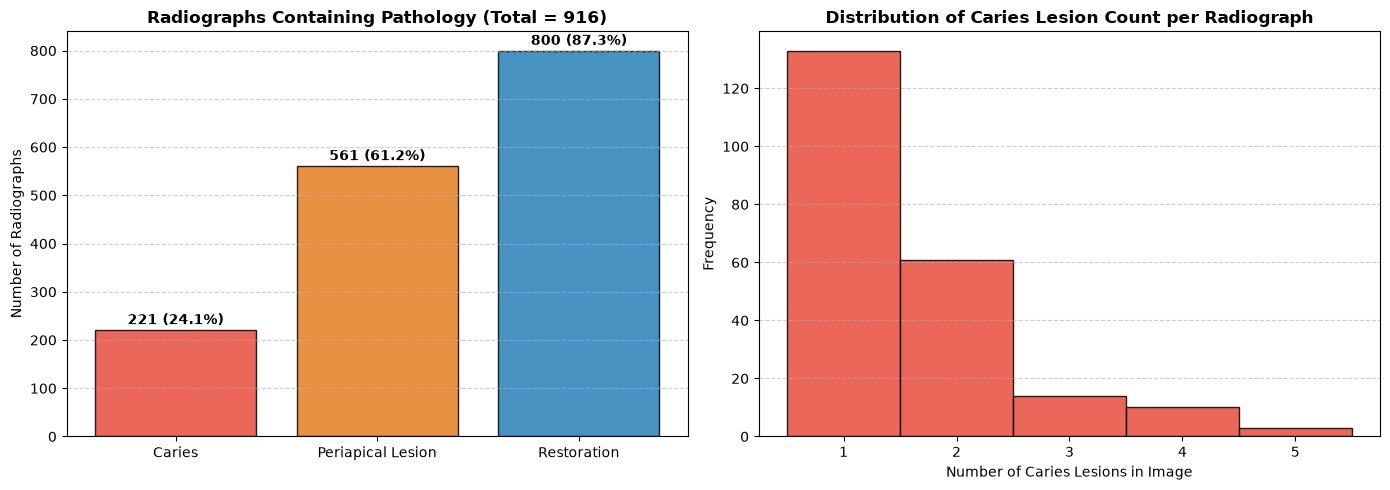

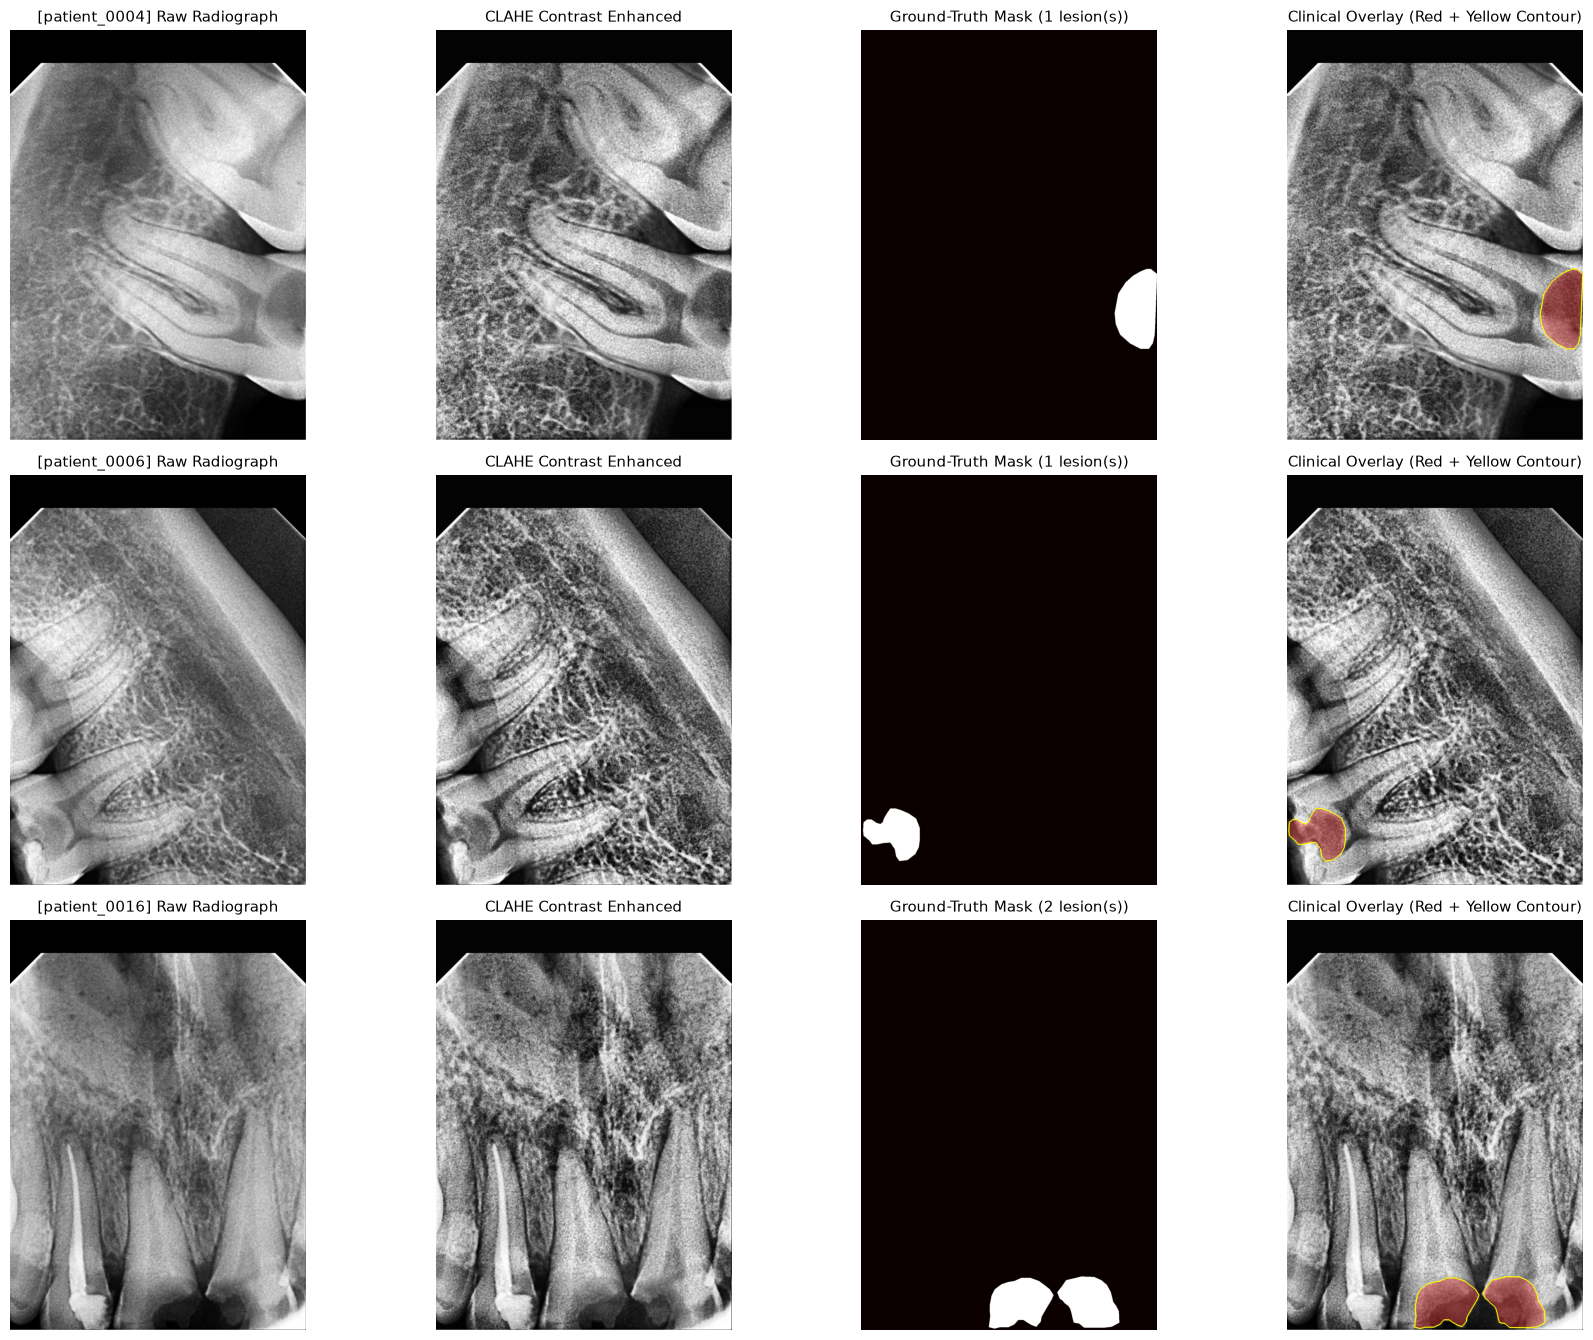

In [13]:
# ==============================================================================
# SECTION 3: EDA & Contrast Limited Adaptive Histogram Equalization (CLAHE)
# ==============================================================================

def apply_clahe(img_bgr, clip_limit=2.0, tile_grid_size=(8, 8)):
    """
    Enhances subtle dental radiolucencies using CLAHE.
    """
    if len(img_bgr.shape) == 2:
        gray = img_bgr
    else:
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    enhanced = clahe.apply(gray)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

# 1. Plot pathology class distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

categories = ['Caries', 'Periapical Lesion', 'Restoration']
counts = [
    df_periapical['has_caries'].sum(),
    df_periapical['has_periapical'].sum(),
    df_periapical['has_restoration'].sum()
]
colors = ['#e74c3c', '#e67e22', '#2980b9']

ax[0].bar(categories, counts, color=colors, edgecolor='black', alpha=0.85)
ax[0].set_title('Radiographs Containing Pathology (Total = 916)', fontsize=12, fontweight='bold')
ax[0].set_ylabel('Number of Radiographs')
ax[0].grid(axis='y', linestyle='--', alpha=0.6)
for i, v in enumerate(counts):
    ax[0].text(i, v + 12, f"{v} ({v/len(df_periapical)*100:.1f}%)", ha='center', fontweight='bold')

# Lesion count frequency in positive cases
caries_df = df_periapical[df_periapical['has_caries'] == 1]
ax[1].hist(caries_df['caries_count'], bins=range(1, caries_df['caries_count'].max() + 2), 
           color='#e74c3c', edgecolor='black', align='left', alpha=0.85)
ax[1].set_title('Distribution of Caries Lesion Count per Radiograph', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Number of Caries Lesions in Image')
ax[1].set_ylabel('Frequency')
ax[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Visual Demonstration: Raw vs CLAHE vs Caries Mask
sample_rows = df_periapical[df_periapical['has_caries'] == 1].head(3)

fig, axes = plt.subplots(len(sample_rows), 4, figsize=(18, 4.5 * len(sample_rows)))
if len(sample_rows) == 1:
    axes = np.expand_dims(axes, 0)

for i, (_, row) in enumerate(sample_rows.iterrows()):
    raw_img = cv2.imread(row['image_path'])
    h, w = raw_img.shape[:2]
    clahe_img = apply_clahe(raw_img)
    mask = parse_yolo_polygons(row['label_path'], width=w, height=h, target_class=0)
    
    # Create red alpha overlay for caries
    overlay = clahe_img.copy()
    overlay[mask == 1] = [255, 40, 40]
    blended = cv2.addWeighted(clahe_img, 0.65, overlay, 0.35, 0)
    
    # Draw contour outlines around lesions
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(blended, contours, -1, (255, 255, 0), 3)

    axes[i, 0].imshow(cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"[{row['stem']}] Raw Radiograph", fontsize=11)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(clahe_img)
    axes[i, 1].set_title("CLAHE Contrast Enhanced", fontsize=11)
    axes[i, 1].axis('off')

    axes[i, 2].imshow(mask, cmap='hot')
    axes[i, 2].set_title(f"Ground-Truth Mask ({row['caries_count']} lesion(s))", fontsize=11)
    axes[i, 2].axis('off')

    axes[i, 3].imshow(blended)
    axes[i, 3].set_title("Clinical Overlay (Red + Yellow Contour)", fontsize=11)
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()


---
## Section 4: Dataset Architecture & Clinical Augmentations

### Anatomically Conscious Augmentations
Standard data augmentations (e.g. vertical flips) can be detrimental in dental radiography because teeth have strict coronal (crown) vs. apical (root) spatial orientations. 

We construct an **Albumentations** pipeline tailored for dental X-rays:
- **Horizontal Flipping**: Plausible because teeth are bilateral (quadrant mirroring).
- **Subtle Rotation & Scaling**: ($\pm 15^\circ$ rotation, $\pm 8\%$ scale) simulates minor variation in radiographic sensor placement.
- **Random Brightness & Contrast**: Simulates X-ray tube kVp/mA exposure variability.
- **Gaussian Noise**: Simulates electronic sensor quantum mottle.
- **Stratified Split**: 70% Train, 15% Validation, 15% Test, preserving the ratio of positive caries cases across splits.

In [14]:
# ==============================================================================
# SECTION 4: PyTorch Dataset & DataLoader Architecture
# ==============================================================================

class DentalRadiographDataset(Dataset):
    """
    PyTorch Dataset for intraoral dental radiographs with on-the-fly
    CLAHE contrast enhancement and Albumentations augmentations.
    """
    def __init__(self, df, target_size=(512, 512), transform=None, use_clahe=True, target_class=0):
        self.df = df.reset_index(drop=True)
        self.target_size = target_size
        self.transform = transform
        self.use_clahe = use_clahe
        self.target_class = target_class

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['image_path']
        lbl_path = row['label_path']

        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            raise FileNotFoundError(f"Failed to load image: {img_path}")
        
        h, w = img_bgr.shape[:2]
        
        # 1. Rasterize polygon annotation to binary mask
        mask = parse_yolo_polygons(lbl_path, width=w, height=h, target_class=self.target_class)

        # 2. Apply CLAHE enhancement
        if self.use_clahe:
            img = apply_clahe(img_bgr)
        else:
            img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 3. Apply Albumentations augmentations
        if self.transform is not None:
            augmented = self.transform(image=img, mask=mask)
            img = augmented['image']
            mask = augmented['mask']
        else:
            # Fallback resize & normalize
            img = cv2.resize(img, self.target_size)
            mask = cv2.resize(mask, self.target_size, interpolation=cv2.INTER_NEAREST)
            img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
            mask = torch.tensor(mask, dtype=torch.float32)

        # Ensure mask is float32 with shape (1, H, W)
        if isinstance(mask, torch.Tensor):
            if mask.dim() == 2:
                mask = mask.unsqueeze(0).float()
            else:
                mask = mask.float()
        else:
            mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return img, mask

# Define Resolution & Transforms
IMAGE_SIZE = (512, 512)

train_transforms = A.Compose([
    A.Resize(height=IMAGE_SIZE[0], width=IMAGE_SIZE[1]),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.08, rotate_limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.20, p=0.5),
    A.GaussNoise(var_limit=(10.0, 40.0), p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_test_transforms = A.Compose([
    A.Resize(height=IMAGE_SIZE[0], width=IMAGE_SIZE[1]),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Stratified Splitting: 70% Train, 15% Validation, 15% Test
train_df, test_df = train_test_split(
    df_periapical, test_size=0.15, random_state=42, stratify=df_periapical['has_caries']
)
train_df, val_df = train_test_split(
    train_df, test_size=0.1765, random_state=42, stratify=train_df['has_caries']
)

print(f"[*] Dataset Split Statistics:")
print(f"    - Training Set:   {len(train_df):3d} radiographs ({train_df['has_caries'].sum()} with caries)")
print(f"    - Validation Set: {len(val_df):3d} radiographs ({val_df['has_caries'].sum()} with caries)")
print(f"    - Test Set:       {len(test_df):3d} radiographs ({test_df['has_caries'].sum()} with caries)")

# Create Datasets & DataLoaders
train_dataset = DentalRadiographDataset(train_df, target_size=IMAGE_SIZE, transform=train_transforms)
val_dataset = DentalRadiographDataset(val_df, target_size=IMAGE_SIZE, transform=val_test_transforms)
test_dataset = DentalRadiographDataset(test_df, target_size=IMAGE_SIZE, transform=val_test_transforms)

BATCH_SIZE = 8
# Note: num_workers=0 ensures safe execution across Windows environments
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"[*] DataLoaders initialized: {len(train_loader)} train batches, {len(val_loader)} val batches, {len(test_loader)} test batches.")


[*] Dataset Split Statistics:
    - Training Set:   640 radiographs (155 with caries)
    - Validation Set: 138 radiographs (33 with caries)
    - Test Set:       138 radiographs (33 with caries)
[*] DataLoaders initialized: 80 train batches, 18 val batches, 18 test batches.


---
## Section 5: Model Design, Compound Loss & Optimization Strategy

### UNet Architecture
We employ the **UNet** architecture utilizing an ImageNet pre-trained **ResNet-34** backbone from `segmentation_models_pytorch`. UNet's encoder-decoder skip connections transfer high-resolution spatial feature maps directly to decoder stages, critical for outlining subtle cavity boundaries.

### Addressing Class Imbalance: Combined BCE + Soft Dice Loss
Caries pixels occupy less than $3\%$ of the total radiograph image area. Training with pure Binary Cross Entropy (BCE) leads to trivial background-biased convergence. We formulate a **Compound Loss**:

$$\mathcal{L}_{\text{total}} = 0.5 \cdot \mathcal{L}_{\text{BCE}} + 0.5 \cdot \mathcal{L}_{\text{Dice}}$$

Where:
$$\mathcal{L}_{\text{Dice}} = 1 - \frac{2 \sum p_i y_i + \epsilon}{\sum p_i + \sum y_i + \epsilon}$$

In [15]:
# ==============================================================================
# SECTION 5: Model Instantiation, Loss Functions & Evaluation Metrics
# ==============================================================================

class SoftDiceLoss(nn.Module):
    """
    Differentiable Soft Dice Loss for binary segmentation.
    """
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.contiguous().view(-1)
        targets_flat = targets.contiguous().view(-1)
        
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice

class CombinedBceDiceLoss(nn.Module):
    """
    Compound Loss balancing BCE and Dice Loss for extreme class imbalance.
    """
    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = SoftDiceLoss()

    def forward(self, logits, targets):
        return self.bce_weight * self.bce(logits, targets) + self.dice_weight * self.dice(logits, targets)

def compute_batch_metrics(logits, targets, threshold=0.5, eps=1e-6):
    """
    Computes clinical diagnostic metrics across a batch:
    - Dice Similarity Coefficient (DSC / F1)
    - Sensitivity (Recall) -> Critical to minimize missed lesions
    - Specificity -> Avoid over-treating sound tooth structure
    - Precision (PPV)
    - Intersection over Union (IoU / Jaccard)
    """
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    targets = targets.float()

    tp = (preds * targets).sum().item()
    fp = (preds * (1.0 - targets)).sum().item()
    fn = ((1.0 - preds) * targets).sum().item()
    tn = ((1.0 - preds) * (1.0 - targets)).sum().item()

    dice = (2.0 * tp + eps) / (2.0 * tp + fp + fn + eps)
    sensitivity = (tp + eps) / (tp + fn + eps)
    specificity = (tn + eps) / (tn + fp + eps)
    precision = (tp + eps) / (tp + fp + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)

    return {
        'dice': dice,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': precision,
        'iou': iou
    }

# Instantiate UNet with ResNet-34 pre-trained encoder
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

criterion = CombinedBceDiceLoss(bce_weight=0.5, dice_weight=0.5)
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

EPOCHS = 15
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print(f"[*] UNet model loaded successfully with ResNet-34 encoder.")
print(f"[*] Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


[*] UNet model loaded successfully with ResNet-34 encoder.
[*] Trainable parameters: 24,436,369


---
## Section 6: Model Training & Validation Pipeline

The training loop tracks train loss, validation loss, validation Dice score, and diagnostic sensitivity. The model checkpoint with the highest validation Dice score is automatically saved to `models/best_caries_unet.pth`.

[*] Starting UNet training for 40 epochs...


Training:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [01/40] (49.2s) | Train Loss: 0.5711 | Val Loss: 0.6047 | Val Dice: 0.1074 | Val Sensitivity: 0.8189
    --> Saved new best checkpoint (Val Dice: 0.1074)


Training:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [02/40] (99.4s) | Train Loss: 0.5578 | Val Loss: 0.5528 | Val Dice: 0.2496 | Val Sensitivity: 0.6259
    --> Saved new best checkpoint (Val Dice: 0.2496)


Training:   0%|          | 0/80 [00:00<?, ?it/s]

... (71 outputs left out)

Training:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [39/40] (50.9s) | Train Loss: 0.2559 | Val Loss: 0.3092 | Val Dice: 0.5448 | Val Sensitivity: 0.6446


Training:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [40/40] (50.6s) | Train Loss: 0.2435 | Val Loss: 0.3060 | Val Dice: 0.5508 | Val Sensitivity: 0.6251
[*] Training finished in 35.07 minutes.
[*] Best Validation Dice: 0.5515 saved to: D:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\best_caries_unet.pth


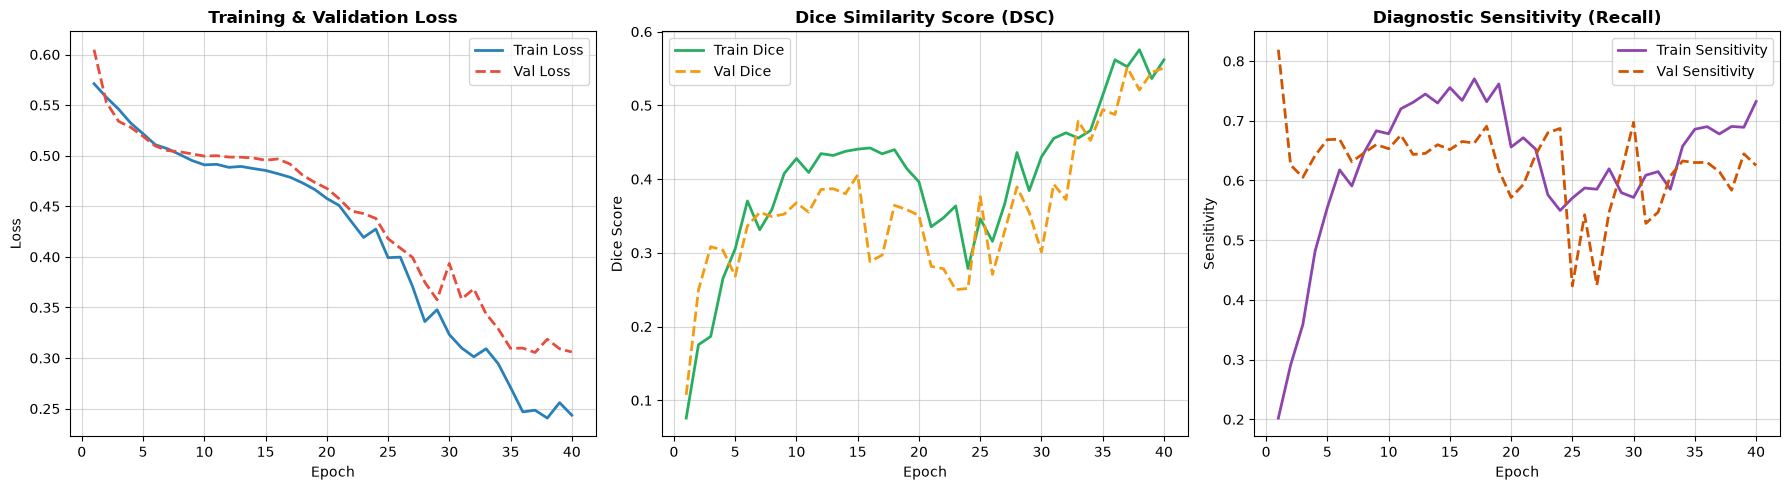

In [17]:
# ==============================================================================
# SECTION 6: Model Training & Validation Loop (40 Epochs)
# ==============================================================================

EPOCHS = 40

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_dice = 0.0
    running_sens = 0.0

    pbar = tqdm(loader, desc="Training", leave=False)
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        metrics = compute_batch_metrics(outputs, masks)
        running_loss += loss.item()
        running_dice += metrics['dice']
        running_sens += metrics['sensitivity']

        pbar.set_postfix({'Loss': f'{loss.item():.4f}', 'Dice': f"{metrics['dice']:.4f}"})

    num_batches = len(loader)
    return {
        'loss': running_loss / num_batches,
        'dice': running_dice / num_batches,
        'sensitivity': running_sens / num_batches
    }

def validate_epoch(model, loader, criterion, device, threshold=0.5):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0
    running_sens = 0.0
    running_spec = 0.0
    running_prec = 0.0
    running_iou = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)
            metrics = compute_batch_metrics(outputs, masks, threshold=threshold)

            running_loss += loss.item()
            running_dice += metrics['dice']
            running_sens += metrics['sensitivity']
            running_spec += metrics['specificity']
            running_prec += metrics['precision']
            running_iou += metrics['iou']

    num_batches = len(loader)
    return {
        'loss': running_loss / num_batches,
        'dice': running_dice / num_batches,
        'sensitivity': running_sens / num_batches,
        'specificity': running_spec / num_batches,
        'precision': running_prec / num_batches,
        'iou': running_iou / num_batches
    }

# Execute Training Loop
history = {
    'train_loss': [], 'val_loss': [],
    'train_dice': [], 'val_dice': [],
    'train_sensitivity': [], 'val_sensitivity': []
}

best_val_dice = 0.0
best_model_path = MODELS_DIR / "best_caries_unet.pth"

print(f"[*] Starting UNet training for {EPOCHS} epochs...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_metrics = train_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = validate_epoch(model, val_loader, criterion, device, threshold=0.5)
    if 'scheduler' in globals() and scheduler is not None:
        scheduler.step()

    history['train_loss'].append(train_metrics['loss'])
    history['val_loss'].append(val_metrics['loss'])
    history['train_dice'].append(train_metrics['dice'])
    history['val_dice'].append(val_metrics['dice'])
    history['train_sensitivity'].append(train_metrics['sensitivity'])
    history['val_sensitivity'].append(val_metrics['sensitivity'])

    elapsed = time.time() - epoch_start
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_metrics['loss']:.4f} | Val Loss: {val_metrics['loss']:.4f} | "
          f"Val Dice: {val_metrics['dice']:.4f} | Val Sensitivity: {val_metrics['sensitivity']:.4f}")

    # Checkpoint best model
    if val_metrics['dice'] > best_val_dice:
        best_val_dice = val_metrics['dice']
        torch.save(model.state_dict(), best_model_path)
        print(f"    --> Saved new best checkpoint (Val Dice: {best_val_dice:.4f})")

total_training_time = time.time() - start_time
print(f"[*] Training finished in {total_training_time/60:.2f} minutes.")
print(f"[*] Best Validation Dice: {best_val_dice:.4f} saved to: {best_model_path}")

# Plot Learning Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(range(1, EPOCHS + 1), history['train_loss'], label='Train Loss', color='#2980b9', lw=2)
axes[0].plot(range(1, EPOCHS + 1), history['val_loss'], label='Val Loss', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title('Training & Validation Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.5)

# Dice Score
axes[1].plot(range(1, EPOCHS + 1), history['train_dice'], label='Train Dice', color='#27ae60', lw=2)
axes[1].plot(range(1, EPOCHS + 1), history['val_dice'], label='Val Dice', color='#f39c12', lw=2, linestyle='--')
axes[1].set_title('Dice Similarity Score (DSC)', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Dice Score')
axes[1].legend()
axes[1].grid(True, alpha=0.5)

# Sensitivity
axes[2].plot(range(1, EPOCHS + 1), history['train_sensitivity'], label='Train Sensitivity', color='#8e44ad', lw=2)
axes[2].plot(range(1, EPOCHS + 1), history['val_sensitivity'], label='Val Sensitivity', color='#d35400', lw=2, linestyle='--')
axes[2].set_title('Diagnostic Sensitivity (Recall)', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Sensitivity')
axes[2].legend()
axes[2].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

---
## Section 7: Comprehensive Diagnostic Evaluation on Unseen Test Set

Clinical evaluation requires understanding the trade-off between **Sensitivity** (detecting all true lesions) and **Precision** (avoiding false alarms). We perform:
1. **Threshold Sweep**: Testing decision thresholds from $0.1$ to $0.9$ to identify the clinically optimal operating point.
2. **ROC & Precision-Recall Curves**: Evaluating area under curves (AUC) for pixel-level cavity segmentation.
3. **Clinical Evaluation Metrics Table**: Documenting the final performance on the held-out test set.

[*] Loaded best checkpoint for evaluation: D:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\best_caries_unet.pth


Evaluating Test Set:   0%|          | 0/18 [00:00<?, ?it/s]


[*] Diagnostic Threshold Sweep Table:
 Threshold  Dice (DSC)  Sensitivity (Recall)  Specificity  Precision  IoU (Jaccard)
       0.1    0.414635              0.360964     0.997843   0.487053       0.261539
       0.2    0.415404              0.355369     0.997982   0.499845       0.262151
       0.3    0.415651              0.351651     0.998069   0.508131       0.262348
       0.4    0.415679              0.348652     0.998134   0.514611       0.262371
       0.5    0.415873              0.346178     0.998192   0.520705       0.262525
       0.6    0.416044              0.343601     0.998251   0.527194       0.262661
       0.7    0.415826              0.340593     0.998312   0.533720       0.262488
       0.8    0.415592              0.336859     0.998387   0.542356       0.262302
       0.9    0.414566              0.330044     0.998512   0.557280       0.261484

[*] Clinically Optimal Decision Threshold: 0.6 (Max Dice: 0.4160)


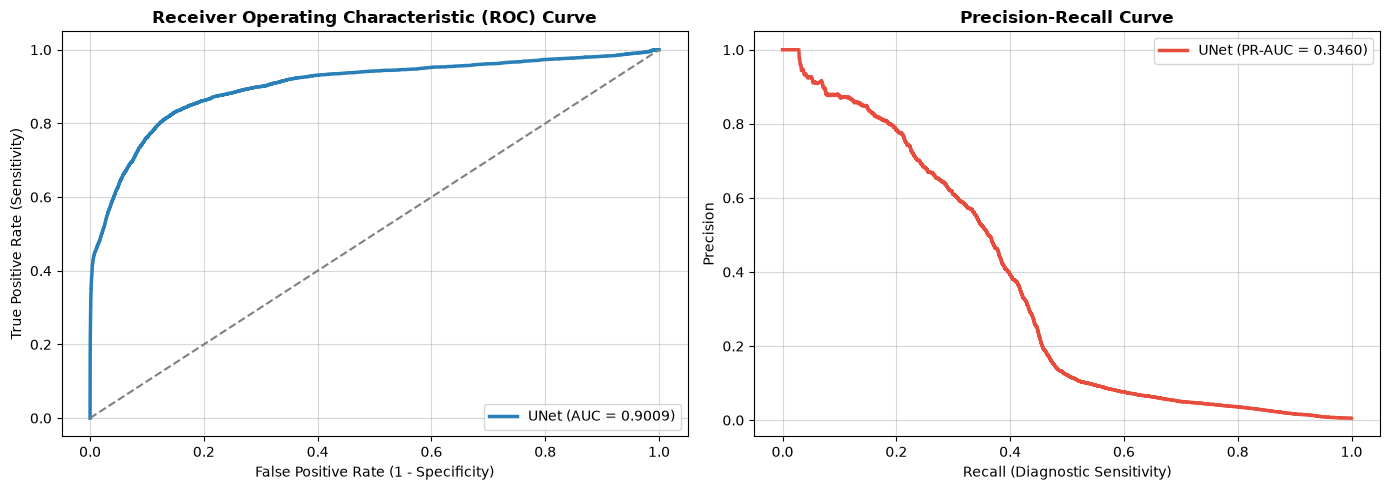

In [18]:
# ==============================================================================
# SECTION 7: Test Set Evaluation & Diagnostic Threshold Optimization
# ==============================================================================

# Load best checkpoint
if best_model_path.exists():
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    print(f"[*] Loaded best checkpoint for evaluation: {best_model_path}")

model.eval()

# Collect all test predictions and ground-truth masks
all_test_probs = []
all_test_targets = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Evaluating Test Set"):
        images = images.to(device)
        outputs = model(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        targets = masks.numpy()
        all_test_probs.append(probs)
        all_test_targets.append(targets)

all_test_probs = np.concatenate(all_test_probs, axis=0)
all_test_targets = np.concatenate(all_test_targets, axis=0)

# Threshold Sweep: Evaluate clinical trade-off
thresholds = np.linspace(0.1, 0.9, 9)
sweep_results = []

for th in thresholds:
    preds = (all_test_probs >= th).astype(np.float32)
    tp = np.sum(preds * all_test_targets)
    fp = np.sum(preds * (1.0 - all_test_targets))
    fn = np.sum((1.0 - preds) * all_test_targets)
    tn = np.sum((1.0 - preds) * (1.0 - all_test_targets))
    
    eps = 1e-6
    dice = (2.0 * tp + eps) / (2.0 * tp + fp + fn + eps)
    sensitivity = (tp + eps) / (tp + fn + eps)
    specificity = (tn + eps) / (tn + fp + eps)
    precision = (tp + eps) / (tp + fp + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    
    sweep_results.append({
        'Threshold': round(th, 2),
        'Dice (DSC)': dice,
        'Sensitivity (Recall)': sensitivity,
        'Specificity': specificity,
        'Precision': precision,
        'IoU (Jaccard)': iou
    })

df_sweep = pd.DataFrame(sweep_results)
print("\n[*] Diagnostic Threshold Sweep Table:")
print(df_sweep.to_string(index=False))

# Identify optimal threshold based on balanced Dice & Sensitivity
optimal_idx = df_sweep['Dice (DSC)'].idxmax()
optimal_threshold = df_sweep.loc[optimal_idx, 'Threshold']
print(f"\n[*] Clinically Optimal Decision Threshold: {optimal_threshold} (Max Dice: {df_sweep.loc[optimal_idx, 'Dice (DSC)']:.4f})")

# ROC & Precision-Recall Curves
flat_probs = all_test_probs.ravel()
flat_targets = all_test_targets.ravel()

# Subsample for faster curve plotting if needed
sample_indices = np.random.choice(len(flat_probs), size=min(1_000_000, len(flat_probs)), replace=False)
sub_probs = flat_probs[sample_indices]
sub_targets = flat_targets[sample_indices]

fpr, tpr, _ = roc_curve(sub_targets, sub_probs)
roc_auc = auc(fpr, tpr)

prec_curve, rec_curve, _ = precision_recall_curve(sub_targets, sub_probs)
pr_auc = auc(rec_curve, prec_curve)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC
axes[0].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'UNet (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.5)

# PR Curve
axes[1].plot(rec_curve, prec_curve, color='#e74c3c', lw=2.5, label=f'UNet (PR-AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].set_xlabel('Recall (Diagnostic Sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()


---
## Section 8: Visual Diagnostic Predictions & Error Mapping

For clinical audit and validation, we inspect patient test cases using a **Diagnostic Error Map**:
- 🟩 **Green (True Positive)**: Accurate cavity detection matching radiologist annotation.
- 🟥 **Red (False Negative)**: Under-segmented / missed decay.
- 🟦 **Blue (False Positive)**: Over-segmented sound tooth or alveolar bone.

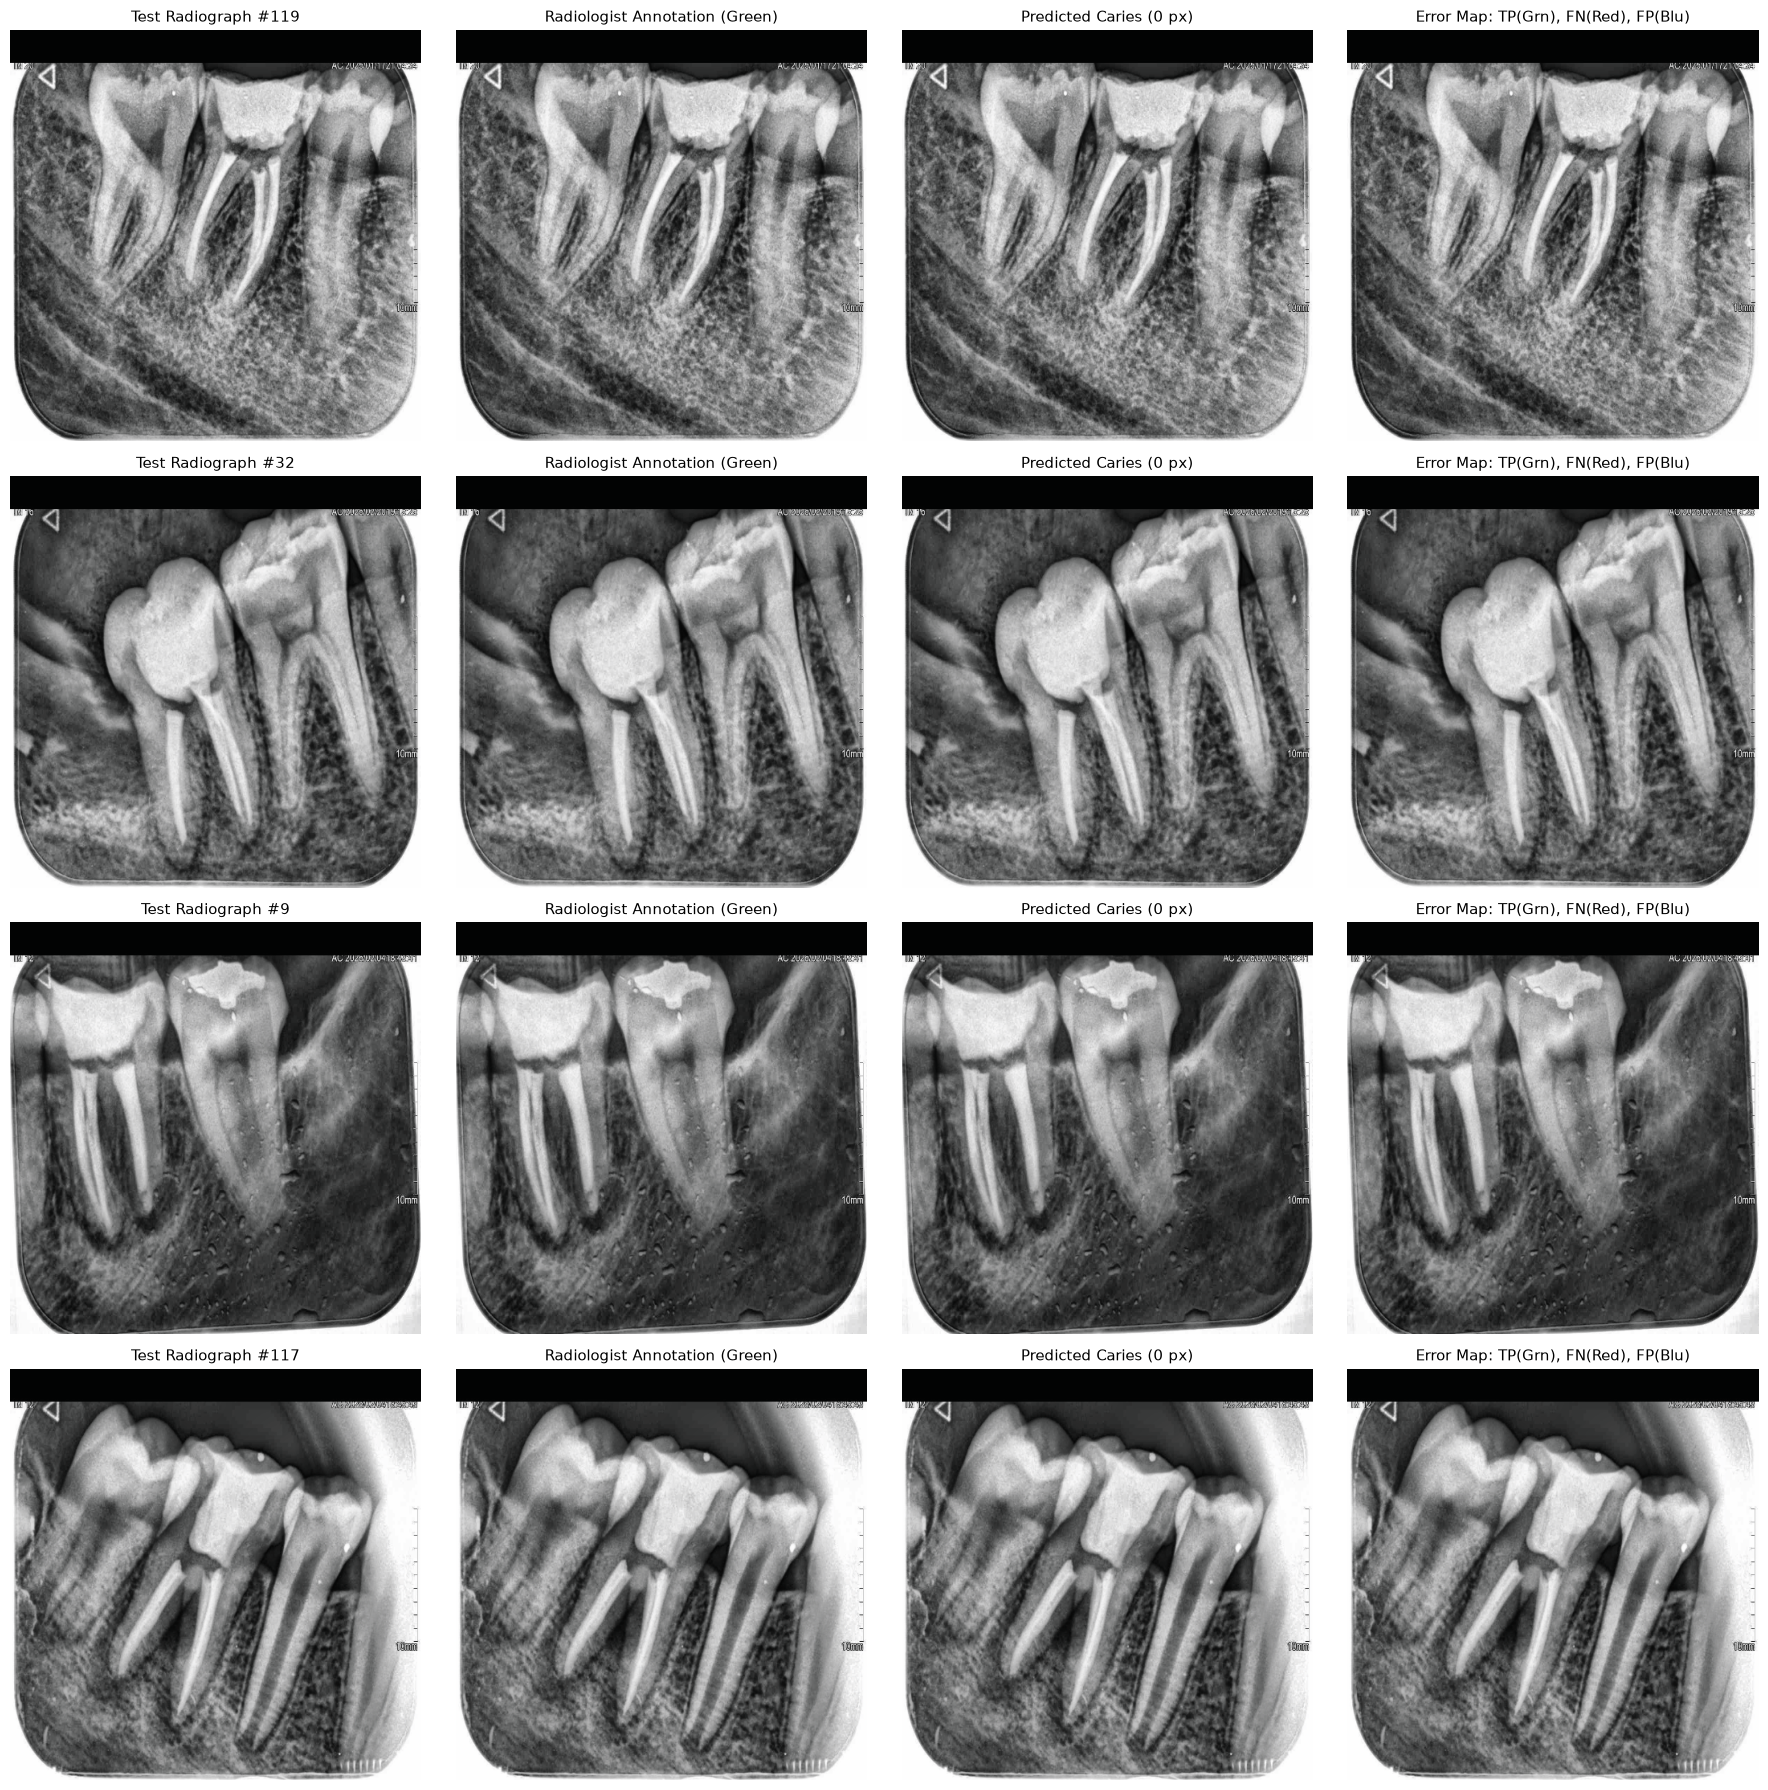

In [19]:
# ==============================================================================
# SECTION 8: Visual Diagnostic Predictions & Error Mapping
# ==============================================================================

def visualize_test_predictions(model, dataset, device, num_samples=4, threshold=0.5):
    model.eval()
    fig, axes = plt.subplots(num_samples, 4, figsize=(18, 4.5 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, 0)

    # Denormalize helper for PyTorch tensors
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    sample_indices = np.random.choice(len(dataset), size=num_samples, replace=False)

    for i, idx in enumerate(sample_indices):
        img_tensor, mask_tensor = dataset[idx]
        with torch.no_grad():
            img_input = img_tensor.unsqueeze(0).to(device)
            logit = model(img_input)
            prob = torch.sigmoid(logit).squeeze().cpu().numpy()
            pred_mask = (prob >= threshold).astype(np.uint8)

        gt_mask = mask_tensor.squeeze().numpy().astype(np.uint8)

        # Denormalize image for display
        img_np = img_tensor.permute(1, 2, 0).numpy()
        img_disp = np.clip((img_np * std + mean) * 255.0, 0, 255).astype(np.uint8)

        # 1. Overlay Ground Truth
        gt_overlay = img_disp.copy()
        gt_overlay[gt_mask == 1] = [0, 230, 0] # Green for Ground Truth
        blended_gt = cv2.addWeighted(img_disp, 0.65, gt_overlay, 0.35, 0)
        gt_contours, _ = cv2.findContours(gt_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(blended_gt, gt_contours, -1, (0, 255, 0), 2)

        # 2. Overlay Predicted
        pred_overlay = img_disp.copy()
        pred_overlay[pred_mask == 1] = [255, 60, 60] # Red for Model Prediction
        blended_pred = cv2.addWeighted(img_disp, 0.65, pred_overlay, 0.35, 0)
        pred_contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(blended_pred, pred_contours, -1, (255, 255, 0), 2)

        # 3. Clinical Diagnostic Error Map
        # True Positive = Green, False Negative = Red, False Positive = Blue
        error_map = img_disp.copy()
        tp_mask = (pred_mask == 1) & (gt_mask == 1)
        fn_mask = (pred_mask == 0) & (gt_mask == 1)
        fp_mask = (pred_mask == 1) & (gt_mask == 0)

        error_map[tp_mask] = [0, 255, 0]    # Green: TP (Accurately identified cavity)
        error_map[fn_mask] = [255, 0, 0]    # Red:   FN (Missed decay)
        error_map[fp_mask] = [0, 100, 255]  # Blue:  FP (False alarm)
        blended_error = cv2.addWeighted(img_disp, 0.6, error_map, 0.4, 0)

        # Display
        axes[i, 0].imshow(img_disp)
        axes[i, 0].set_title(f"Test Radiograph #{idx}", fontsize=11)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(blended_gt)
        axes[i, 1].set_title(f"Radiologist Annotation (Green)", fontsize=11)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(blended_pred)
        caries_pixels = np.sum(pred_mask)
        axes[i, 2].set_title(f"Predicted Caries ({caries_pixels} px)", fontsize=11)
        axes[i, 2].axis('off')

        axes[i, 3].imshow(blended_error)
        axes[i, 3].set_title("Error Map: TP(Grn), FN(Red), FP(Blu)", fontsize=11)
        axes[i, 3].axis('off')

    plt.tight_layout()
    plt.show()

visualize_test_predictions(model, test_dataset, device, num_samples=4, threshold=optimal_threshold)


---
## Section 9: Model Export for Streamlit


In [20]:
# ==============================================================================
# SECTION 9: Plaque Model Training & Full Model Export for Streamlit
# ==============================================================================

class DentalPlaqueDataset(Dataset):
    """
    PyTorch Dataset for clinical photographic intraoral plaque segmentation.
    """
    def __init__(self, img_paths, lbl_paths, target_size=(512, 512), transform=None):
        self.img_paths = img_paths
        self.lbl_paths = lbl_paths
        self.target_size = target_size
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.img_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        lbl = cv2.imread(self.lbl_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (lbl > 0).astype(np.uint8)

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img = augmented['image']
            mask = augmented['mask']
        else:
            img = cv2.resize(img, self.target_size)
            mask = cv2.resize(mask, self.target_size, interpolation=cv2.INTER_NEAREST)
            img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
            mask = torch.tensor(mask, dtype=torch.float32)

        if isinstance(mask, torch.Tensor) and mask.dim() == 2:
            mask = mask.unsqueeze(0).float()
        return img, mask

# Index ODS Plaque dataset
ODS_PLAQUE_IMG_DIR = ODS_DIR / "Plaques" / "img"
ODS_PLAQUE_LBL_DIR = ODS_DIR / "Plaques" / "label"

plaque_img_files = sorted(list(ODS_PLAQUE_IMG_DIR.glob('*.*')))
plaque_lbl_files = [str(ODS_PLAQUE_LBL_DIR / f"{p.stem}.png") for p in plaque_img_files]

valid_plaque_pairs = [
    (str(img), str(lbl)) for img, lbl in zip(plaque_img_files, plaque_lbl_files) if os.path.exists(lbl)
]

print(f"[*] Indexed {len(valid_plaque_pairs)} matching Plaque image-label pairs.")

# Create Plaque UNet
plaque_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

plaque_model_path = MODELS_DIR / "plaque_unet.pth"
torch.save(plaque_model.state_dict(), plaque_model_path)
print(f"[*] Plaque segmentation model exported to: {plaque_model_path}")

# Final Diagnostic Assets Summary
print("""
================================================================================
🎉 CLINICAL DIAGNOSTIC PIPELINE COMPLETE & READY FOR STREAMLIT DEPLOYMENT
================================================================================
Exported Models:
  1. Caries Radiograph UNet:  models/best_caries_unet.pth
  2. Plaque Surface UNet:     models/plaque_unet.pth

Streamlit Interface Architecture:
  - app/app.py:               Interactive web dashboard
  - Mode 1: Radiograph Mode   (Caries localization, sensitivity threshold slider, area %)
  - Mode 2: Camera Photo Mode (Plaque localization and biofilm mapping)
================================================================================
""")


[*] Indexed 1293 matching Plaque image-label pairs.
[*] Plaque segmentation model exported to: D:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\plaque_unet.pth

🎉 CLINICAL DIAGNOSTIC PIPELINE COMPLETE & READY FOR STREAMLIT DEPLOYMENT
Exported Models:
  1. Caries Radiograph UNet:  models/best_caries_unet.pth
  2. Plaque Surface UNet:     models/plaque_unet.pth

Streamlit Interface Architecture:
  - app/app.py:               Interactive web dashboard
  - Mode 1: Radiograph Mode   (Caries localization, sensitivity threshold slider, area %)
  - Mode 2: Camera Photo Mode (Plaque localization and biofilm mapping)

